In [2]:
pip install pandas numpy matplotlib seaborn plotly scikit-learn ipykernel

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import requests
import zipfile
import io
import os
import streamlit as st
import sklearn


In [4]:
#data set main file upload 
URL = "C:\\Users\\djdin\\OneDrive\\Desktop\\Delivery station\\Delivery_station_main_table.xlsx"

In [5]:
zip_finename = "Delivery_station_main_table.xlsx"

In [6]:
df = pd.read_excel(URL) # load the excel file into a pandas DataFrame
df.head() # display the first few rows of the DataFrame

,Operation_ID,Date,Hour,Shift,Process,Work_Area,Packages_Received,Packages_Processed,Backlog,Associates_Planned,Associates_Actual,Labor_Hours,Units_Per_Labor_Hour,Missorts,Problem_Packages,Dispatch_Target,Dispatch_Actual,On_Time_Dispatch,Overtime_Hours
0,1,2026-06-01,02:00,Night,Sortation,Zone_A,625,566,77,10,10,9.99,56.66,4,3,577,593,1,0.0
1,2,2026-06-01,02:00,Night,Staging,Zone_A,331,319,66,7,6,6.26,50.96,3,2,312,356,1,0.0
2,3,2026-06-01,02:00,Night,Sortation,Zone_B,597,526,106,10,10,10.00,52.60,4,3,587,540,0,0.0
3,4,2026-06-01,02:00,Night,Staging,Zone_B,249,252,0,7,7,6.86,36.73,3,0,230,280,1,0.0
4,5,2026-06-01,02:00,Night,Sortation,Zone_C,546,482,79,10,10,10.15,47.49,8,1,537,498,0,0.0


In [7]:
df.info() # get the summary of columns, non-null counts, and data types

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12000 entries, 0 to 11999
Data columns (total 19 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   Operation_ID          12000 non-null  int64         
 1   Date                  12000 non-null  datetime64[ns]
 2   Hour                  12000 non-null  object        
 3   Shift                 12000 non-null  object        
 4   Process               12000 non-null  object        
 5   Work_Area             12000 non-null  object        
 6   Packages_Received     12000 non-null  int64         
 7   Packages_Processed    12000 non-null  int64         
 8   Backlog               12000 non-null  int64         
 9   Associates_Planned    12000 non-null  int64         
 10  Associates_Actual     12000 non-null  int64         
 11  Labor_Hours           12000 non-null  float64       
 12  Units_Per_Labor_Hour  12000 non-null  float64       
 13  Missorts        

In [9]:
# Check for any duplicate rows

duplicates = df.duplicated().sum()
print(f"Number of duplicate rows: {duplicates}")

Number of duplicate rows: 0


In [10]:
# Get statistical summary for numerical columns
df.describe()

,Operation_ID,Date,Packages_Received,Packages_Processed,Backlog,Associates_Planned,Associates_Actual,Labor_Hours,Units_Per_Labor_Hour,Missorts,Problem_Packages,Dispatch_Target,Dispatch_Actual,On_Time_Dispatch,Overtime_Hours
count,12000.00000,12000,12000.000000,12000.000000,12000.000000,12000.000000,12000.000000,12000.000000,12000.000000,12000.000000,12000.000000,12000.000000,12000.000000,12000.000000,12000.000000
mean,6000.50000,2026-08-02 00:00:00.000000256,617.009667,480.473417,192.764167,10.008167,9.938167,9.934774,47.311195,5.195417,3.057500,589.184333,498.639167,0.285917,0.571611
min,1.00000,2026-06-01 00:00:00,142.000000,161.000000,0.000000,6.000000,5.000000,4.790000,26.320000,0.000000,0.000000,140.000000,172.000000,0.000000,0.000000
25%,3000.75000,2026-07-02 00:00:00,392.000000,330.000000,65.000000,8.000000,8.000000,7.790000,43.000000,3.000000,1.000000,375.000000,349.000000,0.000000,0.000000
50%,6000.50000,2026-08-02 00:00:00,541.000000,435.000000,166.000000,9.000000,9.000000,9.080000,47.160000,5.000000,3.000000,518.000000,454.000000,0.000000,0.270000
75%,9000.25000,2026-09-02 00:00:00,824.000000,614.000000,284.000000,12.000000,12.000000,12.060000,51.470000,7.000000,4.000000,788.000000,631.000000,1.000000,0.940000
max,12000.00000,2026-10-03 00:00:00,1697.000000,1232.000000,881.000000,20.000000,20.000000,19.780000,69.490000,22.000000,15.000000,1620.000000,1254.000000,1.000000,4.510000
std,3464.24595,NaN,290.098713,179.915733,152.207048,2.779642,2.795442,2.808183,6.058096,3.223729,2.346661,277.255299,180.015780,0.451869,0.713956


In [13]:
# Count the total missing values for each column
missing_values = df.isna().sum()

print("Missing values per column:")
print(missing_values)

Missing values per column:
Operation_ID            0
Date                    0
Hour                    0
Shift                   0
Process                 0
Work_Area               0
Packages_Received       0
Packages_Processed      0
Backlog                 0
Associates_Planned      0
Associates_Actual       0
Labor_Hours             0
Units_Per_Labor_Hour    0
Missorts                0
Problem_Packages        0
Dispatch_Target         0
Dispatch_Actual         0
On_Time_Dispatch        0
Overtime_Hours          0
dtype: int64


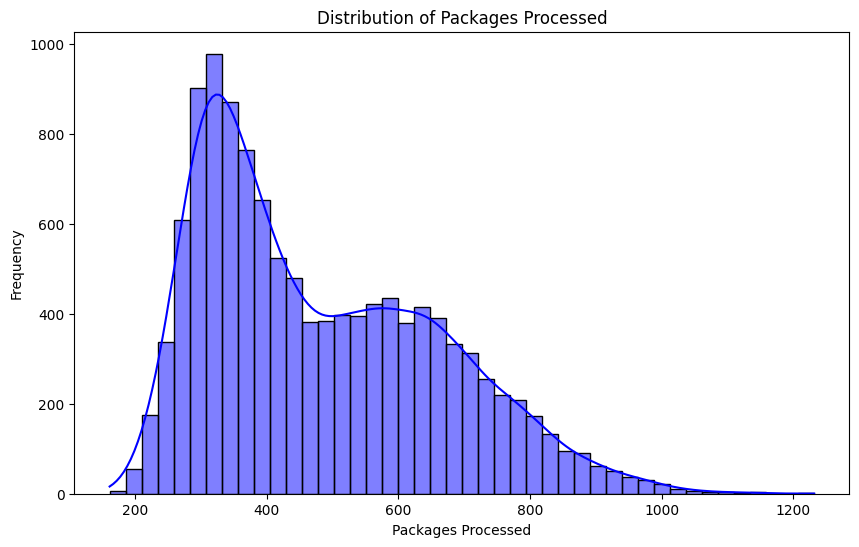

In [ ]:
## Distribution of Packages Processed
## Let's see how many packages are typically processed per hour/shift using a histogram and a Kernel Density Estimate (KDE) plot via Seaborn:

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))
sns.histplot(df['Packages_Processed'], kde=True, color='blue')
plt.title('Distribution of Packages Processed')
plt.xlabel('Packages Processed')
plt.ylabel('Frequency')
plt.show()

C:\Users\djdin\AppData\Local\Temp\ipykernel_25676\1016464209.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Work_Area', y='Packages_Processed', data=df, palette='Set2')


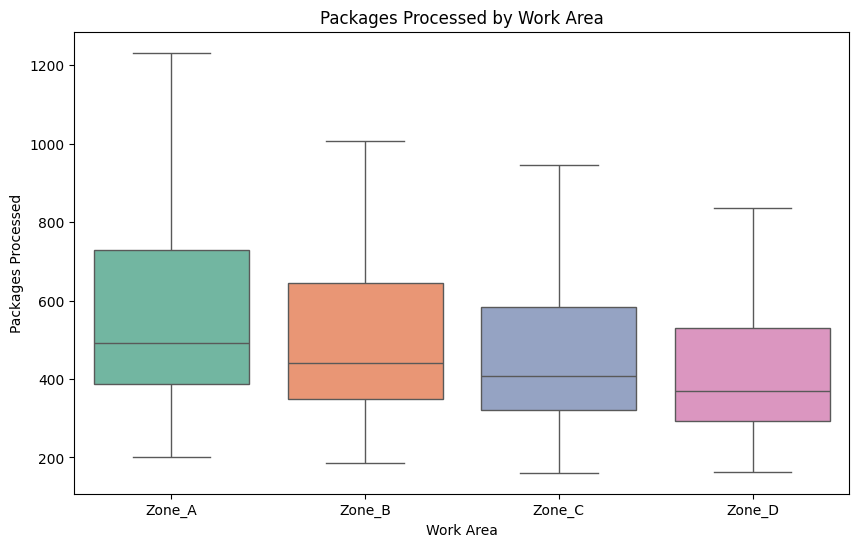

In [15]:
## Packages Processed by Work Area (Boxplot)
## Let's compare performance across different work areas (Zone_A, Zone_B, etc.):


plt.figure(figsize=(10, 6))
sns.boxplot(x='Work_Area', y='Packages_Processed', data=df, palette='Set2')
plt.title('Packages Processed by Work Area')
plt.xlabel('Work Area')
plt.ylabel('Packages Processed')
plt.show()



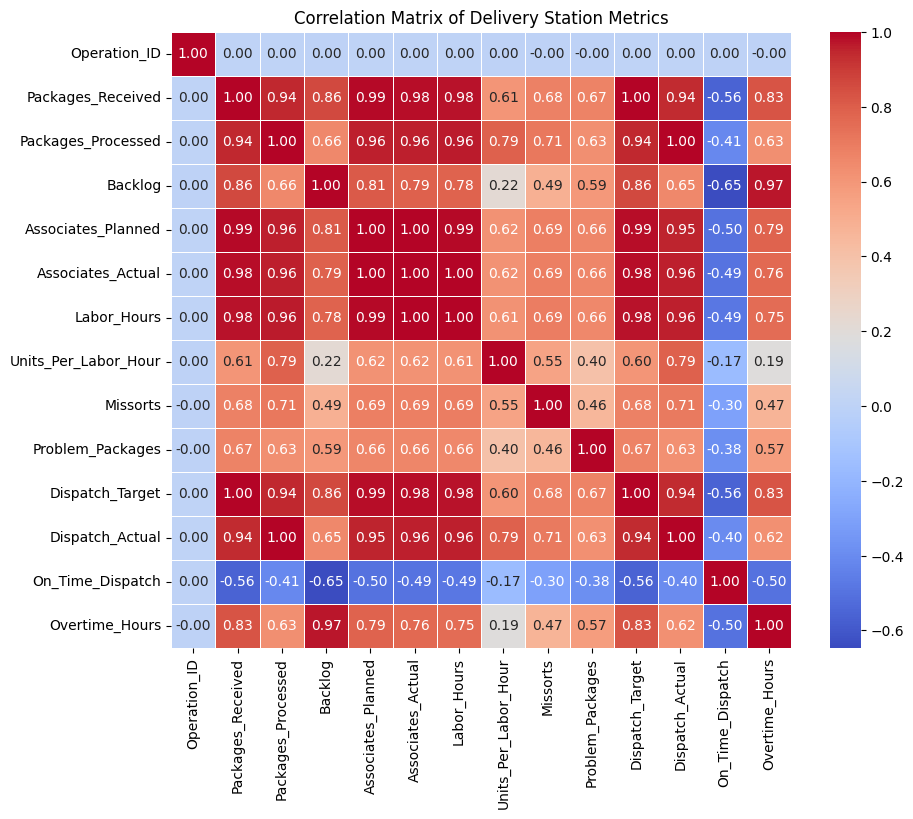

In [16]:
## Correlation Heatmap
## Let's see how numerical variables (like Labor Hours, Missorts, and Packages Processed) relate to each other:


plt.figure(figsize=(10, 8))
# Select only numerical columns for correlation
numeric_df = df.select_dtypes(include=['int64', 'float64'])
sns.heatmap(numeric_df.corr(), annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Correlation Matrix of Delivery Station Metrics')
plt.show()

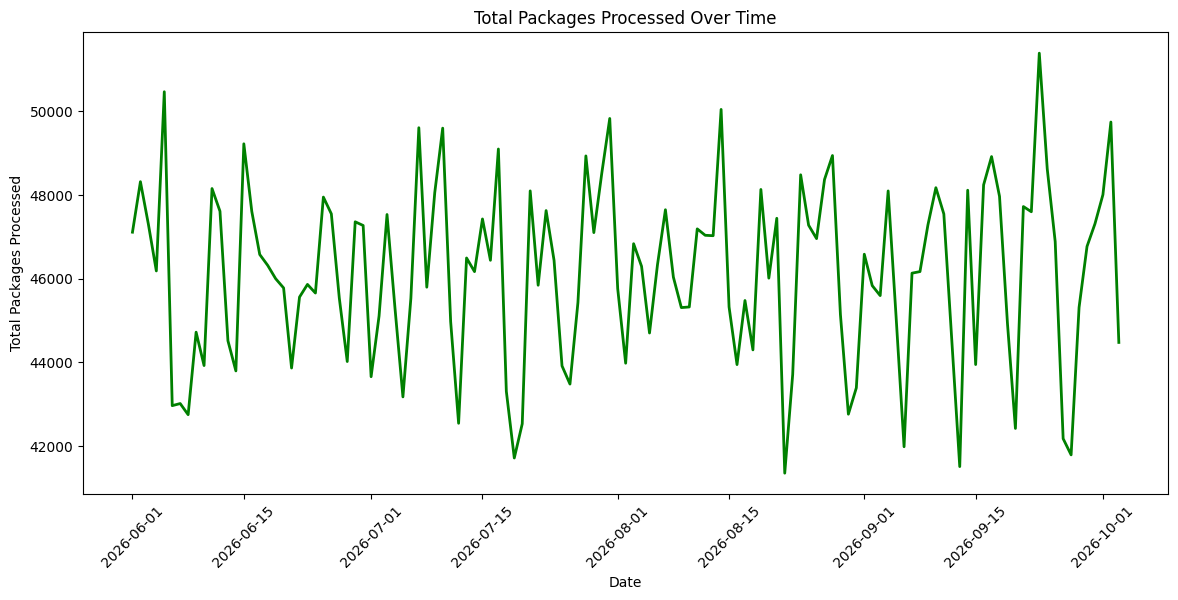

In [17]:
## Time Series Trend (Packages Processed Over Time)
## In a delivery station, spotting daily or hourly trends is crucial for identifying peak operating hours or slowdowns.

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(14, 6))
# Group by Date and sum up packages processed
daily_trend = df.groupby('Date')['Packages_Processed'].sum().reset_index()

sns.lineplot(x='Date', y='Packages_Processed', data=daily_trend, color='green', linewidth=2)
plt.title('Total Packages Processed Over Time')
plt.xlabel('Date')
plt.ylabel('Total Packages Processed')
plt.xticks(rotation=45)
plt.show()

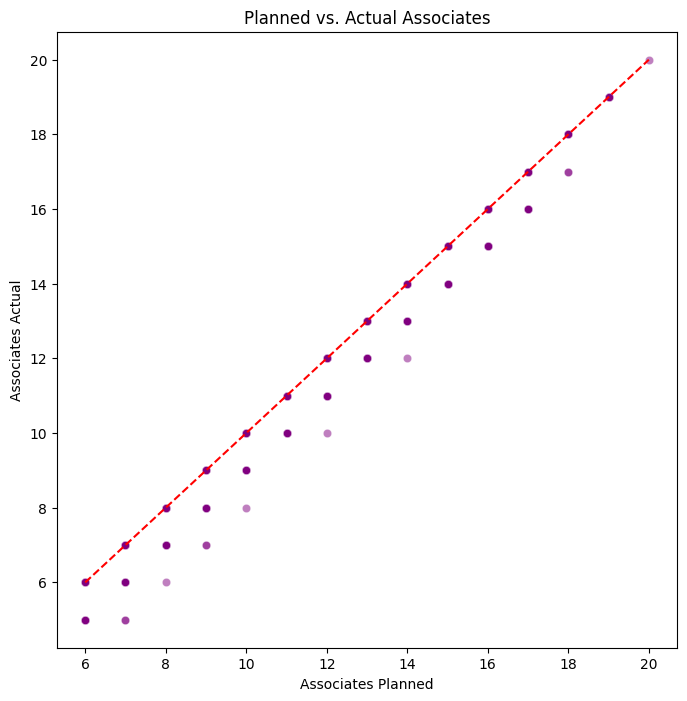

In [19]:
## Staffing Efficiency (Planned vs. Actual Associates)
## This helps you see how closely your station sticks to its planned staffing levels versus how many associates actually showed up.

plt.figure(figsize=(8, 8))
sns.scatterplot(x='Associates_Planned', y='Associates_Actual', data=df, alpha=0.5, color='purple')
plt.title('Planned vs. Actual Associates')
plt.xlabel('Associates Planned')
plt.ylabel('Associates Actual')
# Add a diagonal line for reference (perfect match)
plt.plot([df['Associates_Planned'].min(), df['Associates_Planned'].max()], 
         [df['Associates_Planned'].min(), df['Associates_Planned'].max()], 
         color='red', linestyle='--')
plt.show()

📊 Chart Interpretation Note: Planned vs. Actual Associates
Red Dashed Line: Represents the 1:1 target where Planned = Actual staffing.

Purple Dots Below the Line: Indicate shifts experiencing under-staffing (fewer workers showed up than scheduled).

Key Insight: Notice how many data points (such as when 14 associates are planned) cluster slightly below the red line at 12 or 13 actual workers.

This consistent gap reveals a predictable minor absenteeism trend, 
suggesting management may need to over-schedule by 1–2 staff members to consistently hit target floor numbers.